In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')
from statsmodels.tsa.tsatools import lagmat
from statsmodels.tsa.stattools import adfuller

## Deterministic trends

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


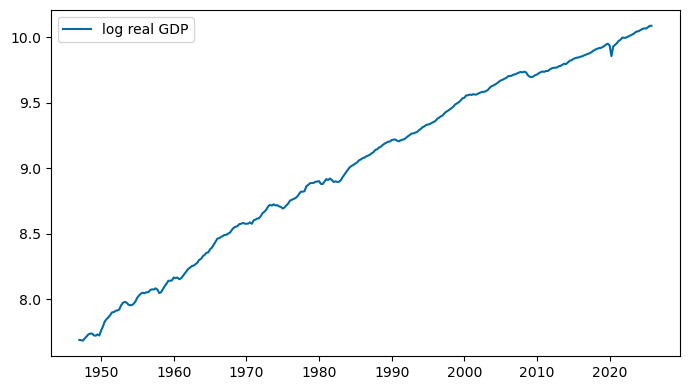

In [2]:
# Load data
df = pd.read_csv('data/GDPC1.csv', index_col='observation_date', parse_dates=True)
l_gdp = np.log(df['GDPC1'])

# Plot data
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(l_gdp.index, l_gdp.values, label='log real GDP')
ax.legend()
plt.tight_layout()
fig.savefig('output/lgdp.eps')
plt.show()

In [3]:
# Trend regression
y = l_gdp.values
T = y.shape[0]
trend = np.arange(T)

# Linear
X_lin = sm.add_constant(trend)
res_lin = sm.OLS(y, X_lin).fit()

# Quadratic
X_quad = sm.add_constant(np.column_stack([trend, trend**2]))
res_quad = sm.OLS(y, X_quad).fit()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


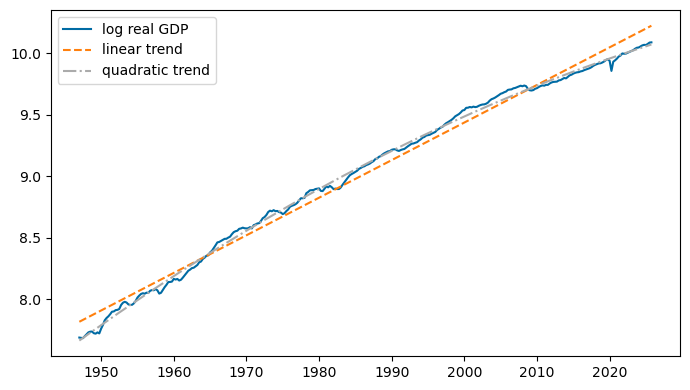

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(l_gdp.index, y, label='log real GDP')
ax.plot(l_gdp.index, res_lin.fittedvalues, '--', label='linear trend')
ax.plot(l_gdp.index, res_quad.fittedvalues, '-.', label='quadratic trend')
ax.legend()
plt.tight_layout()
fig.savefig('output/lgdp_trend.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


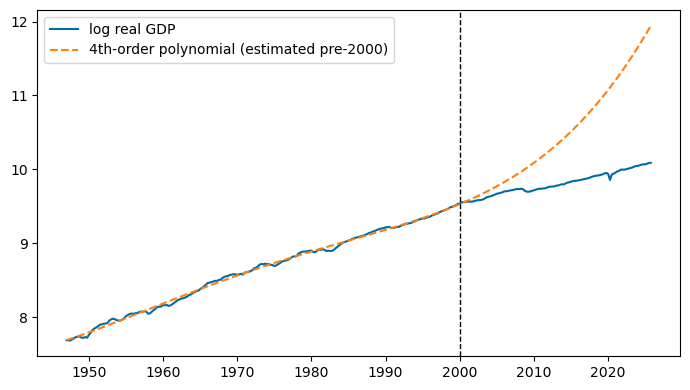

In [5]:
# Polynomial trend regression on pre-2000 sample
poly = 4 # polynomial order
sample = l_gdp.index < '2000'

X_poly = sm.add_constant(np.column_stack([trend**k for k in range(1, poly + 1)]))
res_poly = sm.OLS(y[sample], X_poly[sample]).fit()

# Extrapolate over full sample and plot
l_gdp_poly = res_poly.predict(X_poly)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(l_gdp.index, y, label='log real GDP')
ax.plot(l_gdp.index, l_gdp_poly, '--', label='4th-order polynomial (estimated pre-2000)')
ax.axvline(pd.Timestamp('2000-01-01'), color='k', linestyle='--', linewidth=1)
ax.legend()
plt.tight_layout()
fig.savefig('output/lgdp_poly.eps')
plt.show()

## Random walk

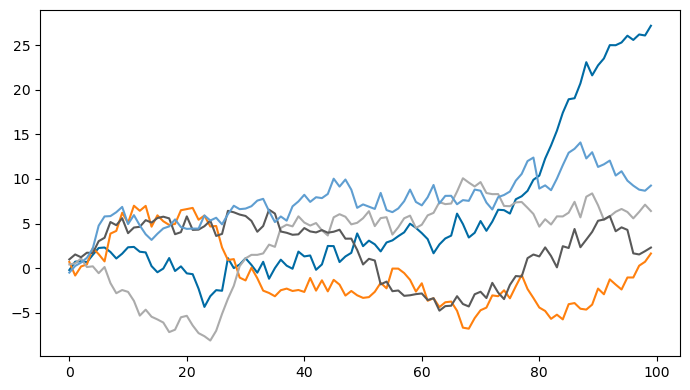

In [6]:
rng = np.random.default_rng(seed=31150)
T_rw = 100
n_paths = 5
u_rw = rng.standard_normal((T_rw, n_paths))
y_rw = np.cumsum(u_rw, axis=0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(T_rw), y_rw)
plt.tight_layout()
fig.savefig('output/rw_sim.eps')
plt.show()

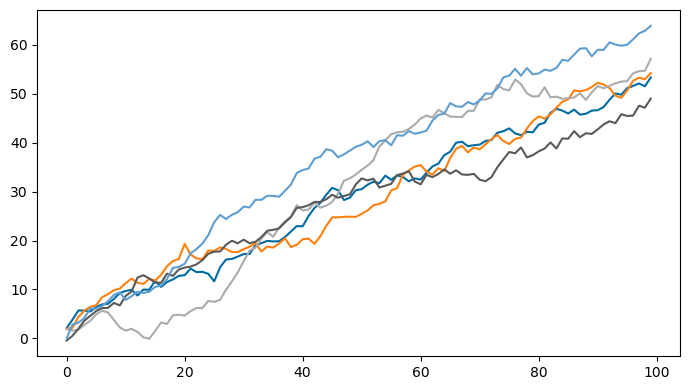

In [7]:
# Random walk with drift
drift = 0.5
u_rw_drift = rng.standard_normal((T_rw, n_paths))
y_rw_drift = np.cumsum(u_rw_drift + drift, axis=0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(T_rw), y_rw_drift)
plt.tight_layout()
fig.savefig('output/rw_drift_sim.eps')
plt.show()

## AR(2) with unit root

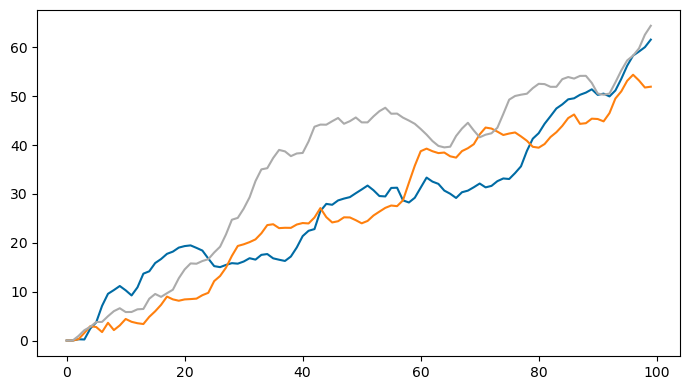

In [8]:
# Simulate
c, a1, a2 = 0.3, 1.5, -0.5
T_ar2 = 100
n_paths_ar2 = 3
u_ar2 = rng.standard_normal((T_ar2, n_paths_ar2))
y_ar2 = np.zeros((T_ar2, n_paths_ar2))
for t in range(2, T_ar2):
    y_ar2[t] = c + a1 * y_ar2[t-1] + a2 * y_ar2[t-2] + u_ar2[t]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(T_ar2), y_ar2)
plt.tight_layout()
fig.savefig('output/unitroot_ar2_sim.eps')
plt.show()

## Unit root simulation study

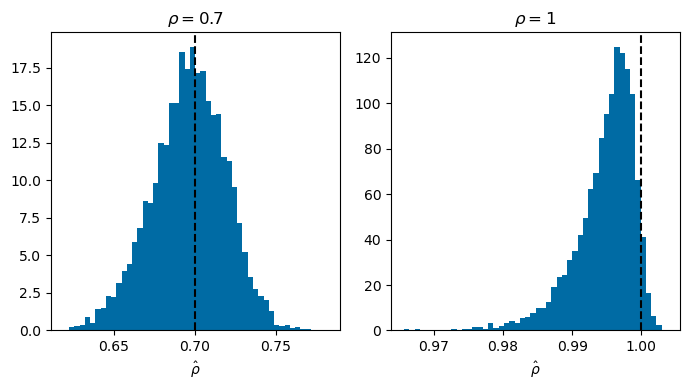

In [9]:
rho_grid = [0.7, 1]
T_sim = 1000
n_sim = 5000

fig, axes = plt.subplots(1, 2, figsize=(7, 4))
for ax, rho in zip(axes, rho_grid):
    rho_hat = np.zeros(n_sim)
    for i in range(n_sim):
        u_sim = rng.standard_normal(T_sim)
        y_sim = np.zeros(T_sim)
        for t in range(1, T_sim):
            y_sim[t] = rho * y_sim[t-1] + u_sim[t]
        X = sm.add_constant(y_sim[:-1])
        rho_hat[i] = sm.OLS(y_sim[1:], X).fit().params[1]
    ax.hist(rho_hat, bins=50, density=True)
    ax.axvline(rho, color='black', linestyle='--')
    ax.set_title(f'$\\rho = {rho}$')
    ax.set_xlabel(r'$\hat{\rho}$')
plt.tight_layout()
fig.savefig('output/unitroot_mc.eps')
plt.show()

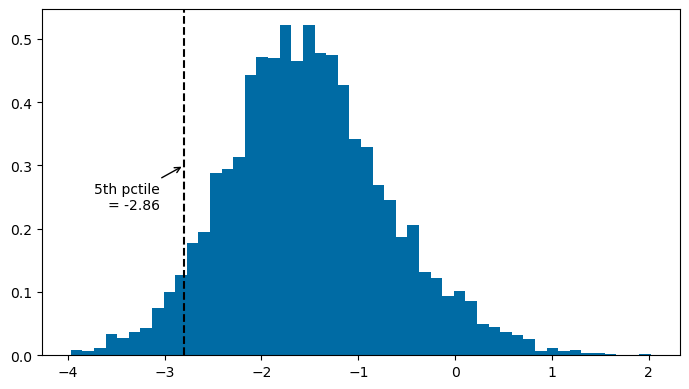

In [10]:
# Dickey-Fuller t-distribution
t_df = np.zeros(n_sim)
for i in range(n_sim):
    u_df = rng.standard_normal(T_sim)
    y_df = np.cumsum(u_df)
    X_df = sm.add_constant(y_df[:-1])
    res_df = sm.OLS(y_df[1:], X_df).fit()
    t_df[i] = (res_df.params[1] - 1) / res_df.bse[1]

q05 = np.quantile(t_df, 0.05)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(t_df, bins=50, density=True)
ax.axvline(q05, color='black', linestyle='--')
ax.annotate(f'5th pctile\n= {-2.86}', # Stock & Watson textbook, Table 15.4
            xy=(q05, 0.3), xytext=(q05 - 0.25, 0.25),
            ha='right', va='center',
            arrowprops=dict(arrowstyle='->'))
plt.tight_layout()
fig.savefig('output/dickey_fuller.eps')
plt.show()

## ADF test for GDP

In [11]:
# Manual ADF test
p = 4
dy = np.diff(y) # GDP growth

X_adf = pd.DataFrame(
    np.column_stack([y[p-1:-1], lagmat(dy, p-1, trim='both')]),
    columns=['y_lag1'] + [f'Dy_lag{k}' for k in range(1, p)],
)
X_adf = sm.add_constant(X_adf)
res_adf = sm.OLS(pd.Series(dy[p-1:], name='dy'), X_adf).fit()
print(res_adf.summary())

                            OLS Regression Results                            
Dep. Variable:                     dy   R-squared:                       0.043
Model:                            OLS   Adj. R-squared:                  0.031
Method:                 Least Squares   F-statistic:                     3.490
Date:                Wed, 03 Jun 2026   Prob (F-statistic):            0.00833
Time:                        14:08:22   Log-Likelihood:                 969.17
No. Observations:                 312   AIC:                            -1928.
Df Residuals:                     307   BIC:                            -1910.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0248      0.008      2.949      0.0

In [12]:
print('Null: RW no drift, alternative: stationary')
adf_stat, p_val, *_ = adfuller(y, maxlag=p-1, regression='c', autolag=None)
print(f't-stat: {adf_stat:.4f}, p-value: {p_val:.4f}')

Null: RW no drift, alternative: stationary
t-stat: -2.2305, p-value: 0.1954


In [13]:
print('Null: RW w/drift, alternative: trend stationary')
adf_stat2, p_val2, *_ = adfuller(y, maxlag=p-1, regression='ct', autolag=None)
print(f't-stat: {adf_stat2:.4f}, p-value: {p_val2:.4f}')

Null: RW w/drift, alternative: trend stationary
t-stat: -1.6259, p-value: 0.7821
